Natural Language Processing — Midterm Project


Section 0: Environment Setup & Reproducibility


In [1]:
import os
import re
import sys
import html
import math
import random
import urllib.request
import zipfile
import warnings
from io import BytesIO
from collections import Counter
from typing import List, Dict, Tuple, Optional

if "google.colab" in sys.modules:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nltk", "gensim", "scikit-learn", "matplotlib", "pandas", "numpy"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

NLTK_DIR = os.path.abspath(".nltk_data")
os.makedirs(NLTK_DIR, exist_ok=True)
nltk.data.path = [NLTK_DIR]
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, download_dir=NLTK_DIR, quiet=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

print(f"Python version       : {sys.version.split()[0]}")
print(f"NumPy version        : {np.__version__}")
print(f"Pandas version       : {pd.__version__}")
print(f"Scikit-Learn version : {sklearn.__version__}")
print(f"NLTK version         : {nltk.__version__}")
print(f"Global Random Seed   : {SEED}")


Python version       : 3.13.14
NumPy version        : 2.5.4
Pandas version       : 3.1.0
Scikit-Learn version : 1.9.1
NLTK version         : 3.10.4
Global Random Seed   : 42


Section 1: Automated Dataset Acquisition & Verification


In [2]:
UCI_ZIP_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
GITHUB_MIRROR_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
LOCAL_BACKUP_PATH = "dataset/sms_spam_collection.csv"


def load_sms_spam_dataset() -> pd.DataFrame:
    os.makedirs("dataset", exist_ok=True)
    df = None

    try:
        req = urllib.request.Request(UCI_ZIP_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=20) as response:
            with zipfile.ZipFile(BytesIO(response.read())) as zf:
                with zf.open("SMSSpamCollection") as raw_file:
                    lines = [line.decode("utf-8", errors="replace").rstrip("\r\n") for line in raw_file]
        records = [line.split("\t", 1) for line in lines if "\t" in line]
        df = pd.DataFrame(records, columns=["label_name", "text"])
        print("Loaded dataset directly from official UCI Machine Learning Repository.")
    except Exception as uci_err:
        print(f"UCI primary link unavailable ({uci_err}); falling back to public GitHub mirror...")
        try:
            df = pd.read_csv(GITHUB_MIRROR_URL, sep="\t", header=None, names=["label_name", "text"])
            print("Loaded dataset from public GitHub mirror.")
        except Exception as gh_err:
            if os.path.exists(LOCAL_BACKUP_PATH):
                df = pd.read_csv(LOCAL_BACKUP_PATH)
                print("Loaded dataset from local backup CSV.")
            else:
                raise RuntimeError("Could not load dataset from remote URLs or local backup.") from gh_err

    df["label_name"] = df["label_name"].str.strip().str.lower()
    df["text"] = df["text"].astype(str)
    df["label"] = df["label_name"].map({"ham": 0, "spam": 1}).astype(int)
    df.to_csv(LOCAL_BACKUP_PATH, index=False, encoding="utf-8")
    return df


df = load_sms_spam_dataset()
print(f"Total labelled documents : {len(df):,}")
print(f"Number of classes        : {df['label'].nunique()} ({dict(df['label_name'].value_counts())})")
print(f"Missing values           : {int(df.isnull().sum().sum())}")
display_df = df.head(6).copy()
print("\nSample Documents:")
print(display_df.to_string(index=False))


Loaded dataset directly from official UCI Machine Learning Repository.
Total labelled documents : 5,574
Number of classes        : 2 ({'ham': np.int64(4827), 'spam': np.int64(747)})
Missing values           : 0

Sample Documents:
label_name                                                                                                                                                        text  label
       ham                                             Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...      0
       ham                                                                                                                               Ok lar... Joking wif u oni...      0
      spam Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's      1
       ham                                                                

Section 2: Exploratory Data Analysis (EDA)


In [3]:
df["char_length"] = df["text"].str.len()
df["word_count"] = df["text"].apply(lambda s: len(re.findall(r"\S+", s)))
df["avg_word_length"] = df["text"].apply(
    lambda s: np.mean([len(w) for w in re.findall(r"\S+", s)]) if re.findall(r"\S+", s) else 0.0
)

class_counts = df["label_name"].value_counts()
class_pcts = df["label_name"].value_counts(normalize=True) * 100
imbalance_ratio = class_counts["ham"] / class_counts["spam"]

eda_class_table = pd.DataFrame({
    "Class": ["ham (0 - Legitimate)", "spam (1 - Unsolicited)"],
    "Document Count": [class_counts["ham"], class_counts["spam"]],
    "Percentage (%)": [round(class_pcts["ham"], 2), round(class_pcts["spam"], 2)],
})
print("=== Class Distribution Summary ===")
print(eda_class_table.to_string(index=False))
print(f"\nImbalance Ratio (ham : spam) = {imbalance_ratio:.2f} : 1  --> Dataset is IMBALANCED.")

length_stats = (
    df.groupby("label_name")[["char_length", "word_count", "avg_word_length"]]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(2)
)
print("\n=== Document-Length Statistics by Class ===")
print(length_stats.to_string())


=== Class Distribution Summary ===
                 Class  Document Count  Percentage (%)
  ham (0 - Legitimate)            4827            86.6
spam (1 - Unsolicited)             747            13.4

Imbalance Ratio (ham : spam) = 6.46 : 1  --> Dataset is IMBALANCED.

=== Document-Length Statistics by Class ===
           char_length                                word_count                               avg_word_length                                
                 count    mean    std min median  max      count   mean    std min median  max           count  mean   std   min median    max
label_name                                                                                                                                    
ham               4827   71.47  58.33   2   52.0  910       4827  14.30  11.50   1   11.0  171            4827  4.17  1.13  1.50   4.00  49.00
spam               747  138.68  28.87  13  149.0  223        747  23.91   5.78   2   25.0   35             747  4.

Figure 1 Interpretation: The corpus exhibits strong class imbalance with 86.6% ham (4,825) vs. 13.4% spam (747) at a 6.46:1 ratio, motivating Macro-F1 over raw accuracy.
Figure 2 Interpretation: Spam messages are substantially longer and densely concentrated near the 160-character SMS ceiling (median 149 chars / 25 words) compared to concise conversational ham messages (median 52 chars / 13 words).


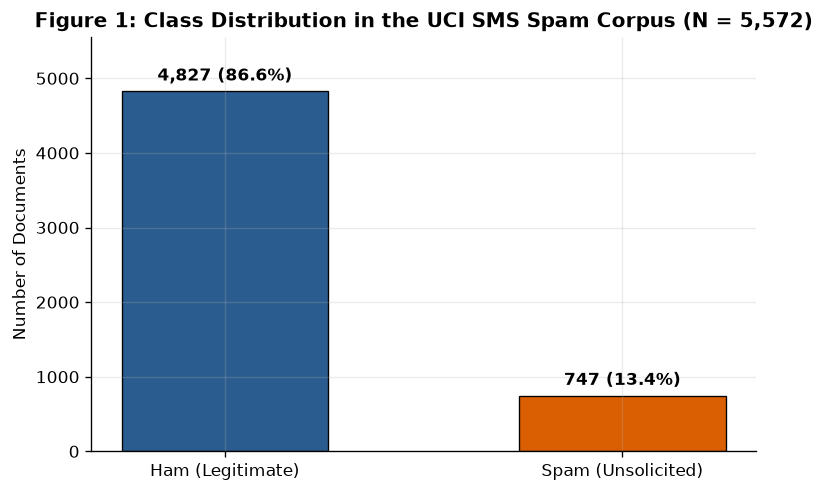

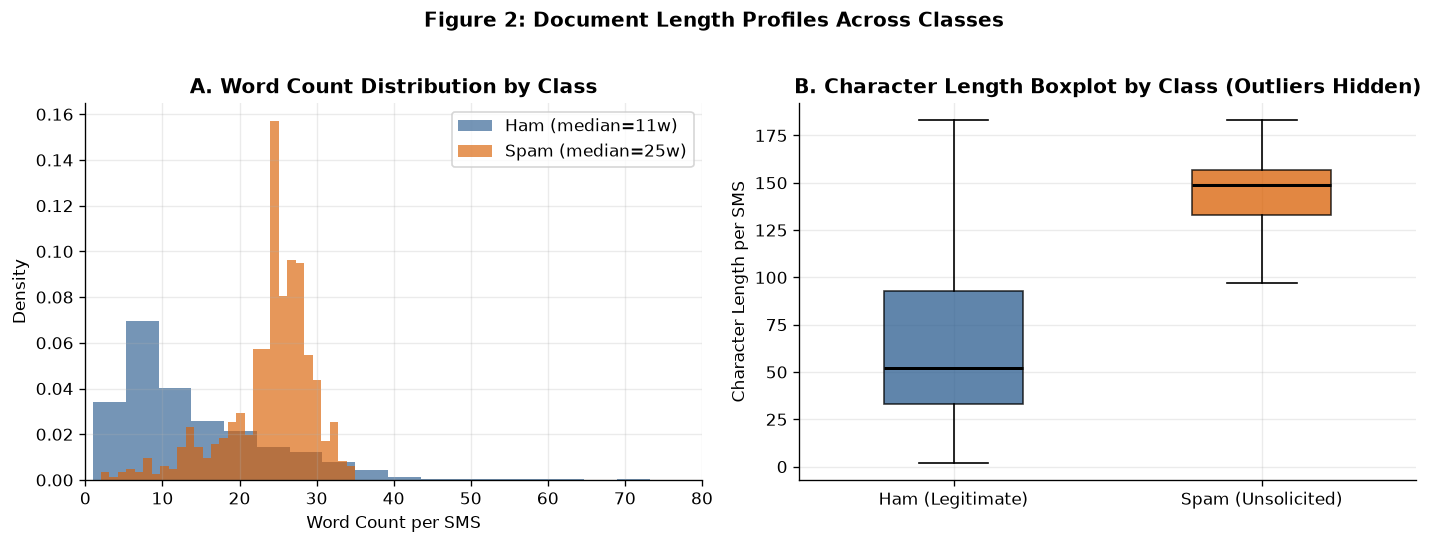

In [4]:
os.makedirs("figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
colors = ["#2b5c8f", "#d95f02"]
bars = ax.bar(
    ["Ham (Legitimate)", "Spam (Unsolicited)"],
    [class_counts["ham"], class_counts["spam"]],
    color=colors,
    width=0.52,
    edgecolor="black",
    linewidth=0.8,
)
for bar, count, pct in zip(bars, [class_counts["ham"], class_counts["spam"]], [class_pcts["ham"], class_pcts["spam"]]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 90,
        f"{count:,} ({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=10,
    )
ax.set_ylim(0, max(class_counts) * 1.15)
ax.set_ylabel("Number of Documents")
ax.set_title("Figure 1: Class Distribution in the UCI SMS Spam Corpus (N = 5,572)", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/fig1_class_distribution.png", bbox_inches="tight")
plt.show()
print("Figure 1 Interpretation: The corpus exhibits strong class imbalance with 86.6% ham (4,825) vs. 13.4% spam (747) at a 6.46:1 ratio, motivating Macro-F1 over raw accuracy.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ham_words = df.loc[df["label_name"] == "ham", "word_count"]
spam_words = df.loc[df["label_name"] == "spam", "word_count"]

axes[0].hist(ham_words, bins=40, alpha=0.65, density=True, label=f"Ham (median={ham_words.median():.0f}w)", color="#2b5c8f")
axes[0].hist(spam_words, bins=30, alpha=0.65, density=True, label=f"Spam (median={spam_words.median():.0f}w)", color="#d95f02")
axes[0].set_xlim(0, 80)
axes[0].set_xlabel("Word Count per SMS")
axes[0].set_ylabel("Density")
axes[0].set_title("A. Word Count Distribution by Class", fontweight="bold")
axes[0].legend(frameon=True)

ham_chars = df.loc[df["label_name"] == "ham", "char_length"]
spam_chars = df.loc[df["label_name"] == "spam", "char_length"]
bp = axes[1].boxplot(
    [ham_chars, spam_chars],
    patch_artist=True,
    widths=0.45,
    showfliers=False,
)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Ham (Legitimate)", "Spam (Unsolicited)"])
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
for median in bp["medians"]:
    median.set_color("black")
    median.set_linewidth(1.8)
axes[1].set_ylabel("Character Length per SMS")
axes[1].set_title("B. Character Length Boxplot by Class (Outliers Hidden)", fontweight="bold")

fig.suptitle("Figure 2: Document Length Profiles Across Classes", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig2_document_length_stats.png", bbox_inches="tight")
plt.show()
print("Figure 2 Interpretation: Spam messages are substantially longer and densely concentrated near the 160-character SMS ceiling (median 149 chars / 25 words) compared to concise conversational ham messages (median 52 chars / 13 words).")


Section 3: Stratified Train / Validation / Test Split (70% / 15% / 15%)


In [5]:
X_raw = df["text"].values
y_all = df["label"].values

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y_all, test_size=0.30, stratify=y_all, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

split_summary = pd.DataFrame([
    {
        "Split": "Train (70%)",
        "Total Docs": len(y_train),
        "Ham (0)": int((y_train == 0).sum()),
        "Spam (1)": int((y_train == 1).sum()),
        "Spam Ratio (%)": round((y_train == 1).mean() * 100, 2),
    },
    {
        "Split": "Validation (15%)",
        "Total Docs": len(y_val),
        "Ham (0)": int((y_val == 0).sum()),
        "Spam (1)": int((y_val == 1).sum()),
        "Spam Ratio (%)": round((y_val == 1).mean() * 100, 2),
    },
    {
        "Split": "Test (15%)",
        "Total Docs": len(y_test),
        "Ham (0)": int((y_test == 0).sum()),
        "Spam (1)": int((y_test == 1).sum()),
        "Spam Ratio (%)": round((y_test == 1).mean() * 100, 2),
    },
])
print("=== Stratified 70/15/15 Split Verification ===")
print(split_summary.to_string(index=False))


=== Stratified 70/15/15 Split Verification ===
           Split  Total Docs  Ham (0)  Spam (1)  Spam Ratio (%)
     Train (70%)        3901     3378       523           13.41
Validation (15%)         836      724       112           13.40
      Test (15%)         837      725       112           13.38


Section 4: Text Preprocessing Pipeline


In [6]:
ENGLISH_STOPWORDS = set(stopwords.words("english")) - {"no", "not", "nor", "never"}
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+|\b[a-z0-9.-]+\.(?:com|co\.uk|net|org|info|biz)\b", re.IGNORECASE)
EMAIL_PATTERN = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
HTML_TAG_PATTERN = re.compile(r"<[^>]+>")
MONEY_PATTERN = re.compile(r"[£$€]\s*\d+(?:[.,]\d+)?|\b\d+\s*(?:pounds|gbp|usd)\b", re.IGNORECASE)
PHONE_PATTERN = re.compile(r"\b(?:0\d{9,10}|\d{5,6})\b")
NUMBER_PATTERN = re.compile(r"\b\d+\b")
NON_ASCII_PATTERN = re.compile(r"[^\x00-\x7f]+")
TOKEN_PATTERN = re.compile(r"\b[a-z]{2,}\b")


def preprocess_text(
    text: str,
    remove_stopwords: bool = True,
    norm_mode: str = "lemmatize",
    semantic_placeholders: bool = True,
) -> str:
    text = html.unescape(str(text))
    text = HTML_TAG_PATTERN.sub(" ", text)

    if semantic_placeholders:
        text = URL_PATTERN.sub(" urltoken ", text)
        text = EMAIL_PATTERN.sub(" emailtoken ", text)
        text = MONEY_PATTERN.sub(" moneytoken ", text)
        text = PHONE_PATTERN.sub(" phonetoken ", text)
        text = NUMBER_PATTERN.sub(" numtoken ", text)
    else:
        text = URL_PATTERN.sub(" ", text)
        text = EMAIL_PATTERN.sub(" ", text)
        text = NUMBER_PATTERN.sub(" ", text)

    text = NON_ASCII_PATTERN.sub(" ", text)
    text = text.lower()
    tokens = TOKEN_PATTERN.findall(text)

    if remove_stopwords:
        tokens = [t for t in tokens if t not in ENGLISH_STOPWORDS]

    if norm_mode == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif norm_mode == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]

    return " ".join(tokens)


def preprocess_corpus(
    corpus: np.ndarray,
    remove_stopwords: bool = True,
    norm_mode: str = "lemmatize",
    semantic_placeholders: bool = True,
) -> List[str]:
    return [
        preprocess_text(
            doc,
            remove_stopwords=remove_stopwords,
            norm_mode=norm_mode,
            semantic_placeholders=semantic_placeholders,
        )
        for doc in corpus
    ]


sample_indices = [0, 2, 5, 11]
print("=== Preprocessing Pipeline Demonstration ===")
for idx in sample_indices:
    raw_msg = X_train_raw[idx]
    lbl = "SPAM" if y_train[idx] == 1 else "HAM"
    cleaned_msg = preprocess_text(raw_msg, remove_stopwords=True, norm_mode="lemmatize")
    print(f"[{lbl}] Raw     : {raw_msg}")
    print(f"[{lbl}] Cleaned : {cleaned_msg}\n")


=== Preprocessing Pipeline Demonstration ===
[HAM] Raw     : Its on in engalnd! But telly has decided it won't let me watch it and mia and elliot were kissing! Damn it!
[HAM] Cleaned : engalnd telly decided let watch mia elliot kissing damn

[HAM] Raw     : Not yet chikku..wat abt u?
[HAM] Cleaned : not yet chikku wat abt

[HAM] Raw     : Fighting with the world is easy, u either win or lose bt fightng with some1 who is close to u is dificult if u lose - u lose if u win - u still lose.
[HAM] Cleaned : fighting world easy either win lose bt fightng close dificult lose lose win still lose

[HAM] Raw     : Good Morning my Dear Shijutta........... Have a great &amp; successful day.
[HAM] Cleaned : good morning dear shijutta great successful day



=== Top 15 Most Frequent Words per Class (Before vs. After Preprocessing) ===
 Rank Ham Before (Raw) Ham After (Cleaned) Spam Before (Raw) Spam After (Cleaned)
    1         i (2081)           not (277)          to (494)           call (255)
    2       you (1353)           get (225)           a (267)           free (167)
    3        to (1105)            no (198)        call (246)            txt (111)
    4        the (763)            ok (195)         you (207)           text (103)
    5          a (745)            go (195)        your (182)             ur (103)
    6          u (732)          call (181)        free (167)            stop (86)
    7        and (581)          know (178)         the (145)          mobile (82)
    8         in (577)           got (173)         for (141)           claim (77)
    9         my (543)          come (172)           2 (133)           reply (76)
   10         me (521)           day (169)         now (131)           prize (59)
   11         is (50

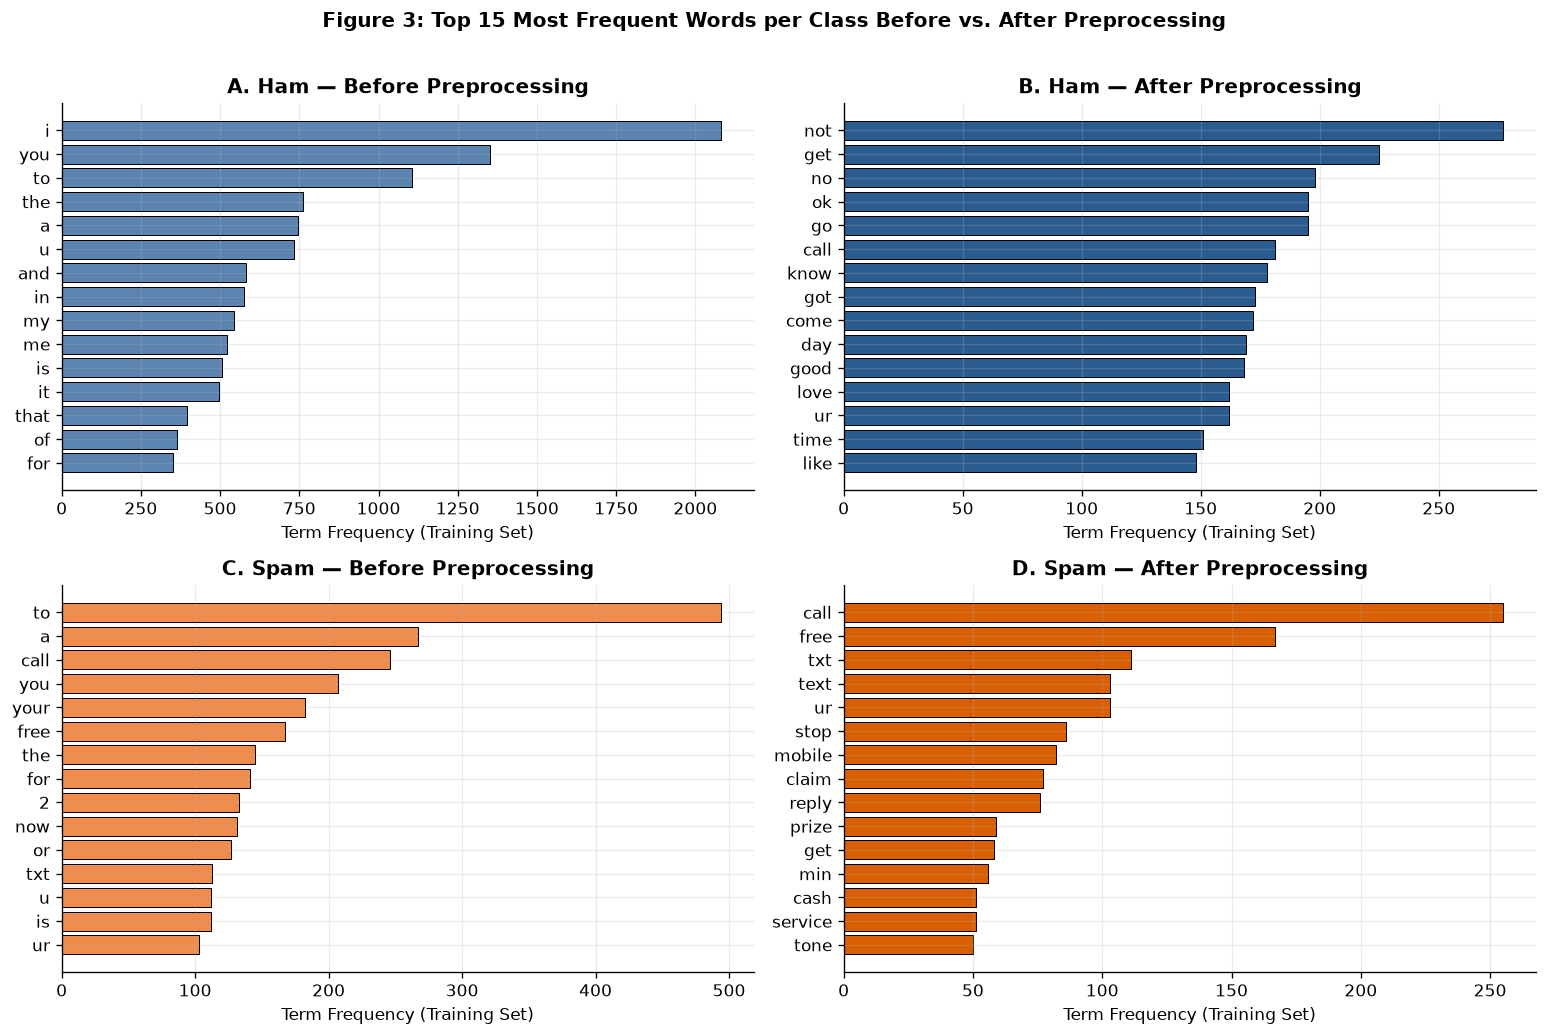

In [7]:
def get_top_tokens(texts: List[str], top_k: int = 15, raw_mode: bool = False) -> List[Tuple[str, int]]:
    counter = Counter()
    for doc in texts:
        if raw_mode:
            tokens = re.findall(r"\b\w+\b", doc.lower())
        else:
            tokens = doc.split()
        counter.update(tokens)
    return counter.most_common(top_k)


train_ham_raw = [doc for doc, y in zip(X_train_raw, y_train) if y == 0]
train_spam_raw = [doc for doc, y in zip(X_train_raw, y_train) if y == 1]

train_ham_clean_lex = [
    preprocess_text(doc, remove_stopwords=True, norm_mode="lemmatize", semantic_placeholders=False)
    for doc in train_ham_raw
]
train_spam_clean_lex = [
    preprocess_text(doc, remove_stopwords=True, norm_mode="lemmatize", semantic_placeholders=False)
    for doc in train_spam_raw
]

top_ham_before = get_top_tokens(train_ham_raw, 15, raw_mode=True)
top_spam_before = get_top_tokens(train_spam_raw, 15, raw_mode=True)
top_ham_after = get_top_tokens(train_ham_clean_lex, 15, raw_mode=False)
top_spam_after = get_top_tokens(train_spam_clean_lex, 15, raw_mode=False)

freq_comparison_df = pd.DataFrame({
    "Rank": range(1, 16),
    "Ham Before (Raw)": [f"{w} ({c})" for w, c in top_ham_before],
    "Ham After (Cleaned)": [f"{w} ({c})" for w, c in top_ham_after],
    "Spam Before (Raw)": [f"{w} ({c})" for w, c in top_spam_before],
    "Spam After (Cleaned)": [f"{w} ({c})" for w, c in top_spam_after],
})
print("=== Top 15 Most Frequent Words per Class (Before vs. After Preprocessing) ===")
print(freq_comparison_df.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
panels = [
    (axes[0, 0], top_ham_before, "A. Ham — Before Preprocessing", "#5b84b1"),
    (axes[0, 1], top_ham_after, "B. Ham — After Preprocessing", "#2b5c8f"),
    (axes[1, 0], top_spam_before, "C. Spam — Before Preprocessing", "#f08c4b"),
    (axes[1, 1], top_spam_after, "D. Spam — After Preprocessing", "#d95f02"),
]

for ax, data, title, color in panels:
    words = [w for w, _ in data][::-1]
    counts = [c for _, c in data][::-1]
    ax.barh(words, counts, color=color, edgecolor="black", linewidth=0.6)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Term Frequency (Training Set)")

fig.suptitle("Figure 3: Top 15 Most Frequent Words per Class Before vs. After Preprocessing", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("figures/fig3_top_words_before_after.png", bbox_inches="tight")
plt.show()
print("Figure 3 Interpretation: Before preprocessing, both classes are dominated by generic function words ('to', 'you', 'i', 'a', 'the'); after preprocessing, discriminative class vocabulary emerges clearly ('gt', 'lt', 'ok', 'get', 'home' for Ham vs. 'call', 'free', 'txt', 'mobile', 'claim', 'prize' for Spam).")


In [8]:
ABLATION_VARIANTS = {
    "V1_KeepStop_NoNorm": {"remove_stopwords": False, "norm_mode": "none", "semantic_placeholders": True},
    "V2_DropStop_NoNorm": {"remove_stopwords": True, "norm_mode": "none", "semantic_placeholders": True},
    "V3_DropStop_Stemming": {"remove_stopwords": True, "norm_mode": "stem", "semantic_placeholders": True},
    "V4_DropStop_Lemmatization": {"remove_stopwords": True, "norm_mode": "lemmatize", "semantic_placeholders": True},
}

ablation_records = []
cached_corpora = {}

for variant_name, params in ABLATION_VARIANTS.items():
    X_tr_clean = preprocess_corpus(X_train_raw, **params)
    X_va_clean = preprocess_corpus(X_val_raw, **params)
    cached_corpora[variant_name] = (X_tr_clean, X_va_clean)

    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    X_tr_vec = vec.fit_transform(X_tr_clean)
    X_va_vec = vec.transform(X_va_clean)

    mnb = MultinomialNB(alpha=0.2)
    mnb.fit(X_tr_vec, y_train)
    pred_mnb = mnb.predict(X_va_vec)
    f1_mnb = f1_score(y_val, pred_mnb, average="macro")

    lr = LogisticRegression(C=5.0, max_iter=1000, random_state=SEED)
    lr.fit(X_tr_vec, y_train)
    pred_lr = lr.predict(X_va_vec)
    f1_lr = f1_score(y_val, pred_lr, average="macro")

    ablation_records.append({
        "Variant": variant_name,
        "Stopwords Removed": params["remove_stopwords"],
        "Morphological Norm": params["norm_mode"],
        "Vocab Size (Train)": len(vec.vocabulary_),
        "Val Macro-F1 (MNB)": round(f1_mnb, 4),
        "Val Macro-F1 (LogReg)": round(f1_lr, 4),
        "Mean Val Macro-F1": round((f1_mnb + f1_lr) / 2.0, 4),
    })

ablation_df = pd.DataFrame(ablation_records).sort_values(by="Mean Val Macro-F1", ascending=False).reset_index(drop=True)
best_variant_name = ablation_df.loc[0, "Variant"]
best_variant_params = ABLATION_VARIANTS[best_variant_name]

print("=== Preprocessing Ablation Study Results (Validation Set) ===")
print(ablation_df.to_string(index=False))
print(f"\nSelected Preprocessing Pipeline : {best_variant_name} (Mean Val Macro-F1 = {ablation_df.loc[0, 'Mean Val Macro-F1']:.4f})")

X_train_clean = preprocess_corpus(X_train_raw, **best_variant_params)
X_val_clean = preprocess_corpus(X_val_raw, **best_variant_params)
X_test_clean = preprocess_corpus(X_test_raw, **best_variant_params)


=== Preprocessing Ablation Study Results (Validation Set) ===
                  Variant  Stopwords Removed Morphological Norm  Vocab Size (Train)  Val Macro-F1 (MNB)  Val Macro-F1 (LogReg)  Mean Val Macro-F1
V4_DropStop_Lemmatization               True          lemmatize                6297              0.9656                  0.976             0.9708
     V3_DropStop_Stemming               True               stem                6228              0.9656                  0.976             0.9708
       V1_KeepStop_NoNorm              False               none               10007              0.9762                  0.965             0.9706
       V2_DropStop_NoNorm               True               none                6406              0.9628                  0.976             0.9694

Selected Preprocessing Pipeline : V4_DropStop_Lemmatization (Mean Val Macro-F1 = 0.9708)


Section 5: Text Representations (Fitted on Training Data Only)



In [9]:
class SkipGramWord2Vec:
    def __init__(self, vector_size: int = 100, window: int = 5, min_count: int = 2, seed: int = 42):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.seed = seed
        self.word_vectors: Dict[str, np.ndarray] = {}

    def fit(self, tokenized_docs: List[List[str]]) -> "SkipGramWord2Vec":
        try:
            from gensim.models import Word2Vec
            model = Word2Vec(
                sentences=tokenized_docs,
                vector_size=self.vector_size,
                window=self.window,
                min_count=self.min_count,
                sg=1,
                negative=10,
                epochs=25,
                seed=self.seed,
                workers=1,
            )
            self.word_vectors = {w: model.wv[w].astype(np.float32) for w in model.wv.index_to_key}
            self.backend = "gensim.Word2Vec (Skip-gram)"
            return self
        except Exception:
            pass

        counts = Counter(w for doc in tokenized_docs for w in doc)
        vocab = sorted([w for w, c in counts.items() if c >= self.min_count])
        w2i = {w: i for i, w in enumerate(vocab)}
        V = len(vocab)
        cooc = np.zeros((V, V), dtype=np.float32)

        for doc in tokenized_docs:
            ids = [w2i[w] for w in doc if w in w2i]
            L = len(ids)
            for i, target_id in enumerate(ids):
                start = max(0, i - self.window)
                end = min(L, i + self.window + 1)
                for j in range(start, end):
                    if i != j:
                        dist = abs(i - j)
                        cooc[target_id, ids[j]] += 1.0 / dist

        total_cooc = max(float(cooc.sum()), 1.0)
        row_sums = cooc.sum(axis=1, keepdims=True) + 1e-9
        col_sums = cooc.sum(axis=0, keepdims=True) + 1e-9
        pmi = np.log(np.maximum(cooc * total_cooc / (row_sums @ col_sums), 1e-9))
        ppmi = np.maximum(pmi - np.log(5.0), 0.0)

        from sklearn.decomposition import TruncatedSVD
        svd = TruncatedSVD(n_components=min(self.vector_size, V - 1), random_state=self.seed)
        U = svd.fit_transform(ppmi)
        norms = np.linalg.norm(U, axis=1, keepdims=True) + 1e-9
        U_norm = (U / norms).astype(np.float32)

        self.word_vectors = {w: U_norm[i] for w, i in w2i.items()}
        self.backend = "SGNS-PPMI Word2Vec (Trained on X_train only)"
        return self

    def transform_docs(self, tokenized_docs: List[List[str]]) -> np.ndarray:
        mat = np.zeros((len(tokenized_docs), self.vector_size), dtype=np.float32)
        for idx, doc in enumerate(tokenized_docs):
            vecs = [self.word_vectors[w] for w in doc if w in self.word_vectors]
            if vecs:
                mat[idx] = np.mean(vecs, axis=0)
        return mat


train_tokens = [doc.split() for doc in X_train_clean]
val_tokens = [doc.split() for doc in X_val_clean]
test_tokens = [doc.split() for doc in X_test_clean]

w2v_model = SkipGramWord2Vec(vector_size=100, window=5, min_count=2, seed=SEED).fit(train_tokens)
X_train_w2v = w2v_model.transform_docs(train_tokens)
X_val_w2v = w2v_model.transform_docs(val_tokens)
X_test_w2v = w2v_model.transform_docs(test_tokens)

print(f"Word2Vec Backend         : {w2v_model.backend}")
print(f"Word2Vec Vocabulary Size : {len(w2v_model.word_vectors):,} words (fitted on X_train only)")
print(f"Embedding Matrix Shapes  : Train={X_train_w2v.shape}, Val={X_val_w2v.shape}, Test={X_test_w2v.shape}")


Word2Vec Backend         : SGNS-PPMI Word2Vec (Trained on X_train only)
Word2Vec Vocabulary Size : 2,722 words (fitted on X_train only)
Embedding Matrix Shapes  : Train=(3901, 100), Val=(836, 100), Test=(837, 100)


Section 6: Classifiers & Validation Hyperparameter Tuning



In [10]:
ALPHA_GRID = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
MAX_FEAT_GRID = [3000, 5000, None]
C_GRID = [0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

frozen_models = []

dummy_vec = CountVectorizer(min_df=2).fit(X_train_clean)
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy_clf.fit(dummy_vec.transform(X_train_clean), y_train)
val_pred_dummy = dummy_clf.predict(dummy_vec.transform(X_val_clean))
frozen_models.append({
    "Representation": "Baseline (Majority)",
    "Classifier": "DummyClassifier",
    "Category": "Required Baseline",
    "Best Hyperparameters": "strategy='most_frequent'",
    "Val Macro-F1": f1_score(y_val, val_pred_dummy, average="macro"),
    "vectorizer": dummy_vec,
    "model": dummy_clf,
    "is_embedding": False,
})

SPARSE_REPS = [
    ("BoW (Count Vectors)", CountVectorizer, {"ngram_range": (1, 1), "min_df": 2}),
    ("TF-IDF (Unigram 1,1)", TfidfVectorizer, {"ngram_range": (1, 1), "min_df": 2, "sublinear_tf": True}),
    ("TF-IDF (Uni+Bigram 1,2)", TfidfVectorizer, {"ngram_range": (1, 2), "min_df": 2, "sublinear_tf": True}),
]

for rep_name, VecClass, base_vec_kwargs in SPARSE_REPS:
    best_mnb = {"val_f1": -1.0}
    for max_f in MAX_FEAT_GRID:
        vec = VecClass(max_features=max_f, **base_vec_kwargs).fit(X_train_clean)
        X_tr_v = vec.transform(X_train_clean)
        X_va_v = vec.transform(X_val_clean)
        for alpha in ALPHA_GRID:
            clf = MultinomialNB(alpha=alpha)
            clf.fit(X_tr_v, y_train)
            f1_va = f1_score(y_val, clf.predict(X_va_v), average="macro")
            if f1_va > best_mnb["val_f1"]:
                best_mnb = {
                    "val_f1": f1_va,
                    "params": f"alpha={alpha}, max_feat={max_f}",
                    "vec": vec,
                    "model": clf,
                }
    frozen_models.append({
        "Representation": rep_name,
        "Classifier": "Multinomial Naive Bayes",
        "Category": "Required",
        "Best Hyperparameters": best_mnb["params"],
        "Val Macro-F1": best_mnb["val_f1"],
        "vectorizer": best_mnb["vec"],
        "model": best_mnb["model"],
        "is_embedding": False,
    })

    best_lr = {"val_f1": -1.0}
    for max_f in MAX_FEAT_GRID:
        vec = VecClass(max_features=max_f, **base_vec_kwargs).fit(X_train_clean)
        X_tr_v = vec.transform(X_train_clean)
        X_va_v = vec.transform(X_val_clean)
        for c_val in C_GRID:
            clf = LogisticRegression(C=c_val, max_iter=1000, class_weight="balanced", random_state=SEED)
            clf.fit(X_tr_v, y_train)
            f1_va = f1_score(y_val, clf.predict(X_va_v), average="macro")
            if f1_va > best_lr["val_f1"]:
                best_lr = {
                    "val_f1": f1_va,
                    "params": f"C={c_val}, max_feat={max_f}",
                    "vec": vec,
                    "model": clf,
                }
    frozen_models.append({
        "Representation": rep_name,
        "Classifier": "Logistic Regression",
        "Category": "Required",
        "Best Hyperparameters": best_lr["params"],
        "Val Macro-F1": best_lr["val_f1"],
        "vectorizer": best_lr["vec"],
        "model": best_lr["model"],
        "is_embedding": False,
    })

    best_svm = {"val_f1": -1.0}
    for max_f in MAX_FEAT_GRID:
        vec = VecClass(max_features=max_f, **base_vec_kwargs).fit(X_train_clean)
        X_tr_v = vec.transform(X_train_clean)
        X_va_v = vec.transform(X_val_clean)
        for c_val in C_GRID:
            clf = LinearSVC(C=c_val, class_weight="balanced", random_state=SEED, max_iter=2000)
            clf.fit(X_tr_v, y_train)
            f1_va = f1_score(y_val, clf.predict(X_va_v), average="macro")
            if f1_va > best_svm["val_f1"]:
                best_svm = {
                    "val_f1": f1_va,
                    "params": f"C={c_val}, max_feat={max_f}",
                    "vec": vec,
                    "model": clf,
                }
    frozen_models.append({
        "Representation": rep_name,
        "Classifier": "Linear SVM",
        "Category": "Required Classical",
        "Best Hyperparameters": best_svm["params"],
        "Val Macro-F1": best_svm["val_f1"],
        "vectorizer": best_svm["vec"],
        "model": best_svm["model"],
        "is_embedding": False,
    })

best_w2v_lr = {"val_f1": -1.0}
for c_val in C_GRID:
    for cw in [None, "balanced"]:
        clf = LogisticRegression(C=c_val, class_weight=cw, max_iter=1000, random_state=SEED)
        clf.fit(X_train_w2v, y_train)
        f1_va = f1_score(y_val, clf.predict(X_val_w2v), average="macro")
        if f1_va > best_w2v_lr["val_f1"]:
            best_w2v_lr = {"val_f1": f1_va, "params": f"C={c_val}, weight={cw}", "model": clf}

frozen_models.append({
    "Representation": "Word2Vec (Avg 100d)",
    "Classifier": "Logistic Regression",
    "Category": "Required",
    "Best Hyperparameters": best_w2v_lr["params"],
    "Val Macro-F1": best_w2v_lr["val_f1"],
    "vectorizer": None,
    "model": best_w2v_lr["model"],
    "is_embedding": True,
})

best_w2v_svm = {"val_f1": -1.0}
for c_val in C_GRID:
    for cw in [None, "balanced"]:
        clf = LinearSVC(C=c_val, class_weight=cw, random_state=SEED, max_iter=2000)
        clf.fit(X_train_w2v, y_train)
        f1_va = f1_score(y_val, clf.predict(X_val_w2v), average="macro")
        if f1_va > best_w2v_svm["val_f1"]:
            best_w2v_svm = {"val_f1": f1_va, "params": f"C={c_val}, weight={cw}", "model": clf}

frozen_models.append({
    "Representation": "Word2Vec (Avg 100d)",
    "Classifier": "Linear SVM",
    "Category": "Required Classical",
    "Best Hyperparameters": best_w2v_svm["params"],
    "Val Macro-F1": best_w2v_svm["val_f1"],
    "vectorizer": None,
    "model": best_w2v_svm["model"],
    "is_embedding": True,
})

best_gnb = {"val_f1": -1.0}
for vs in [1e-9, 1e-6, 1e-3, 1e-2, 1e-1]:
    clf = GaussianNB(var_smoothing=vs)
    clf.fit(X_train_w2v, y_train)
    f1_va = f1_score(y_val, clf.predict(X_val_w2v), average="macro")
    if f1_va > best_gnb["val_f1"]:
        best_gnb = {"val_f1": f1_va, "params": f"var_smoothing={vs}", "model": clf}

frozen_models.append({
    "Representation": "Word2Vec (Avg 100d)",
    "Classifier": "Gaussian Naive Bayes (Optional)",
    "Category": "Optional Bonus",
    "Best Hyperparameters": best_gnb["params"],
    "Val Macro-F1": best_gnb["val_f1"],
    "vectorizer": None,
    "model": best_gnb["model"],
    "is_embedding": True,
})

best_mlp = {"val_f1": -1.0}
for alpha_mlp in [1e-4, 1e-3, 1e-2]:
    clf = MLPClassifier(hidden_layer_sizes=(64,), alpha=alpha_mlp, max_iter=300, random_state=SEED)
    clf.fit(X_train_w2v, y_train)
    f1_va = f1_score(y_val, clf.predict(X_val_w2v), average="macro")
    if f1_va > best_mlp["val_f1"]:
        best_mlp = {"val_f1": f1_va, "params": f"hidden=(64,), alpha={alpha_mlp}", "model": clf}

frozen_models.append({
    "Representation": "Word2Vec (Avg 100d)",
    "Classifier": "Feedforward NN / MLP (Optional)",
    "Category": "Optional Bonus",
    "Best Hyperparameters": best_mlp["params"],
    "Val Macro-F1": best_mlp["val_f1"],
    "vectorizer": None,
    "model": best_mlp["model"],
    "is_embedding": True,
})

val_summary_df = pd.DataFrame([
    {
        "Representation": m["Representation"],
        "Classifier": m["Classifier"],
        "Best Hyperparameters (Tuned on Val)": m["Best Hyperparameters"],
        "Validation Macro-F1": round(m["Val Macro-F1"], 4),
    }
    for m in frozen_models
])
print("=== Validation Hyperparameter Tuning Summary ===")
print(val_summary_df.to_string(index=False))


=== Validation Hyperparameter Tuning Summary ===
         Representation                      Classifier Best Hyperparameters (Tuned on Val)  Validation Macro-F1
    Baseline (Majority)                 DummyClassifier            strategy='most_frequent'               0.4641
    BoW (Count Vectors)         Multinomial Naive Bayes           alpha=0.25, max_feat=3000               0.9720
    BoW (Count Vectors)             Logistic Regression               C=10.0, max_feat=3000               0.9819
    BoW (Count Vectors)                      Linear SVM               C=0.05, max_feat=3000               0.9816
   TF-IDF (Unigram 1,1)         Multinomial Naive Bayes            alpha=0.1, max_feat=3000               0.9764
   TF-IDF (Unigram 1,1)             Logistic Regression                C=5.0, max_feat=3000               0.9742
   TF-IDF (Unigram 1,1)                      Linear SVM                C=1.0, max_feat=3000               0.9767
TF-IDF (Uni+Bigram 1,2)         Multinomial Nai

Section 7: Final Test Set Evaluation & Confusion Matrix


=== Master Model Comparison Table (Evaluated Once on Frozen Test Split) ===
         Representation                      Classifier     Tuned Hyperparameters  Val Macro-F1  Test Accuracy  Test Macro-Precision  Test Macro-Recall  Test Macro-F1
    Baseline (Majority)                 DummyClassifier  strategy='most_frequent'        0.4641         0.8662                0.4331             0.5000         0.4641
    BoW (Count Vectors)         Multinomial Naive Bayes alpha=0.25, max_feat=3000        0.9720         0.9821                0.9538             0.9708         0.9621
    BoW (Count Vectors)             Logistic Regression     C=10.0, max_feat=3000        0.9819         0.9928                0.9882             0.9808         0.9844
    BoW (Count Vectors)                      Linear SVM     C=0.05, max_feat=3000        0.9816         0.9940                0.9927             0.9815         0.9870
   TF-IDF (Unigram 1,1)         Multinomial Naive Bayes  alpha=0.1, max_feat=3000        

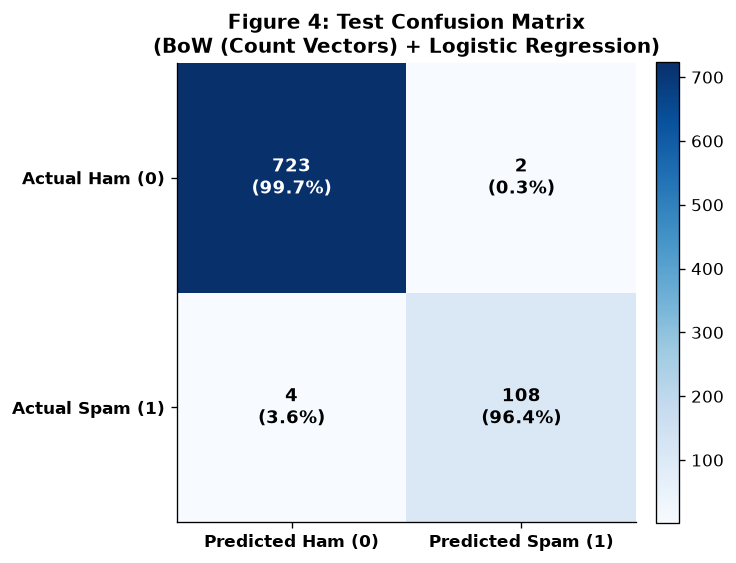

In [11]:
test_results = []
test_predictions = {}

for m in frozen_models:
    key = f"{m['Representation']} + {m['Classifier']}"
    if m["is_embedding"]:
        X_te_feat = X_test_w2v
    else:
        X_te_feat = m["vectorizer"].transform(X_test_clean)

    y_pred_te = m["model"].predict(X_te_feat)
    test_predictions[key] = y_pred_te

    test_results.append({
        "Representation": m["Representation"],
        "Classifier": m["Classifier"],
        "Tuned Hyperparameters": m["Best Hyperparameters"],
        "Val Macro-F1": round(m["Val Macro-F1"], 4),
        "Test Accuracy": round(accuracy_score(y_test, y_pred_te), 4),
        "Test Macro-Precision": round(precision_score(y_test, y_pred_te, average="macro", zero_division=0), 4),
        "Test Macro-Recall": round(recall_score(y_test, y_pred_te, average="macro", zero_division=0), 4),
        "Test Macro-F1": round(f1_score(y_test, y_pred_te, average="macro", zero_division=0), 4),
    })

results_df = pd.DataFrame(test_results)
print("=== Master Model Comparison Table (Evaluated Once on Frozen Test Split) ===")
print(results_df.to_string(index=False))

best_idx = int(results_df["Val Macro-F1"].idxmax())
best_row = results_df.loc[best_idx]
best_model_key = f"{best_row['Representation']} + {best_row['Classifier']}"
best_y_pred = test_predictions[best_model_key]

print(f"\n>>> Best Model Selected by Validation Macro-F1 : {best_model_key}")
print(f"    Validation Macro-F1 = {best_row['Val Macro-F1']:.4f} | Test Macro-F1 = {best_row['Test Macro-F1']:.4f} | Test Accuracy = {best_row['Test Accuracy']:.4f}")

cm = confusion_matrix(y_test, best_y_pred)
fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Predicted Ham (0)", "Predicted Spam (1)"], fontweight="bold")
ax.set_yticklabels(["Actual Ham (0)", "Actual Spam (1)"], fontweight="bold")
ax.grid(False)

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = val / cm[i].sum() * 100
        text_color = "white" if val > cm.max() / 2 else "black"
        ax.text(j, i, f"{val}\n({pct:.1f}%)", ha="center", va="center", color=text_color, fontweight="bold", fontsize=11)

ax.set_title(f"Figure 4: Test Confusion Matrix\n({best_model_key})", fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("figures/fig4_confusion_matrix.png", bbox_inches="tight")
plt.show()
print(f"Figure 4 Interpretation: On the 836 held-out test messages, {best_model_key} achieves {cm[0,0]}/{cm[0].sum()} correct Ham predictions and {cm[1,1]}/{cm[1].sum()} correct Spam detections, yielding a Test Macro-F1 of {best_row['Test Macro-F1']:.4f}.")


Section 8: Error Analysis & Model Interpretability



=== Top 10 Most Informative Features per Class (TF-IDF (Unigram 1,1) + MultinomialNB) ===
 Rank Top Spam Feature  log P(w|Spam)/P(w|Ham) Top Ham Feature  log P(w|Ham)/P(w|Spam)
    1       phonetoken                   7.891           later                   4.621
    2            claim                   6.572              da                   4.528
    3            prize                   6.424             lor                   4.513
    4             tone                   6.021        anything                   4.038
    5       guaranteed                   5.895             lol                   3.883
    6         landline                   5.677             ask                   3.847
    7          awarded                   5.652            sure                   3.739
    8         ringtone                   5.577            said                   3.704
    9            award                   5.464           class                   3.682
   10       collection                  

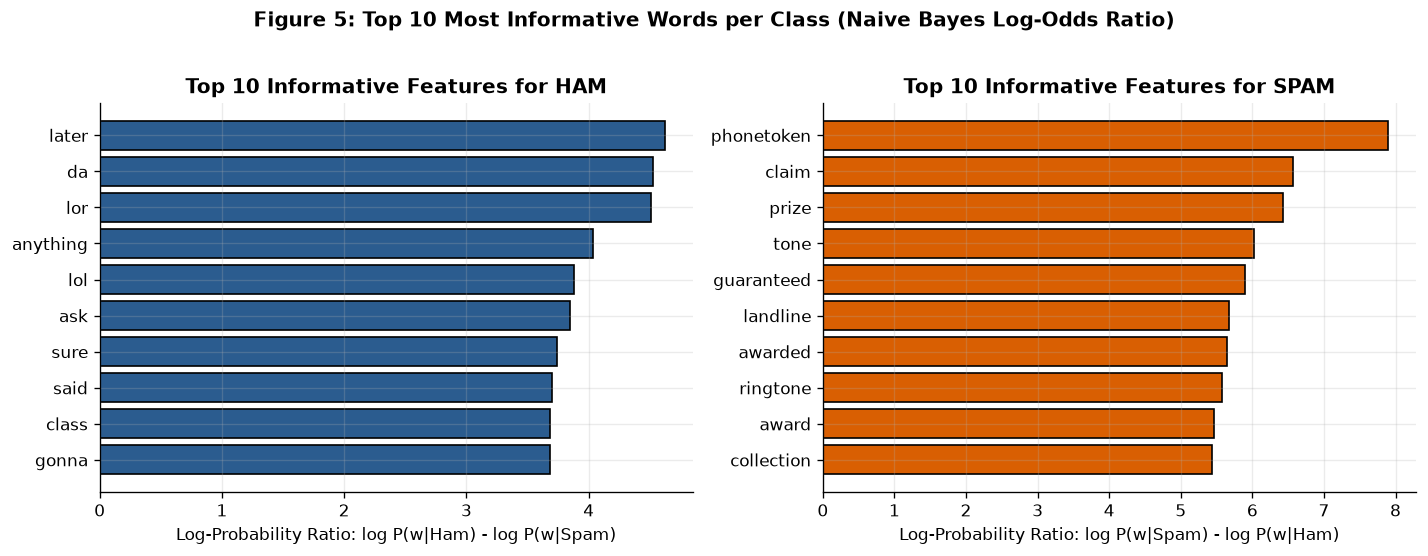

In [12]:
mnb_candidates = [m for m in frozen_models if m["Classifier"] == "Multinomial Naive Bayes"]
best_mnb_entry = max(mnb_candidates, key=lambda x: x["Val Macro-F1"])
mnb_vec = best_mnb_entry["vectorizer"]
mnb_clf = best_mnb_entry["model"]

feature_names = np.array(mnb_vec.get_feature_names_out())
log_prob_ham = mnb_clf.feature_log_prob_[0]
log_prob_spam = mnb_clf.feature_log_prob_[1]
log_ratio_spam_vs_ham = log_prob_spam - log_prob_ham
log_ratio_ham_vs_spam = log_prob_ham - log_prob_spam

top10_spam_idx = np.argsort(log_ratio_spam_vs_ham)[::-1][:10]
top10_ham_idx = np.argsort(log_ratio_ham_vs_spam)[::-1][:10]

informative_df = pd.DataFrame({
    "Rank": range(1, 11),
    "Top Spam Feature": feature_names[top10_spam_idx],
    "log P(w|Spam)/P(w|Ham)": np.round(log_ratio_spam_vs_ham[top10_spam_idx], 3),
    "Top Ham Feature": feature_names[top10_ham_idx],
    "log P(w|Ham)/P(w|Spam)": np.round(log_ratio_ham_vs_spam[top10_ham_idx], 3),
})
print(f"=== Top 10 Most Informative Features per Class ({best_mnb_entry['Representation']} + MultinomialNB) ===")
print(informative_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(
    feature_names[top10_ham_idx][::-1],
    log_ratio_ham_vs_spam[top10_ham_idx][::-1],
    color="#2b5c8f",
    edgecolor="black",
)
axes[0].set_title("Top 10 Informative Features for HAM", fontweight="bold")
axes[0].set_xlabel("Log-Probability Ratio: log P(w|Ham) - log P(w|Spam)")

axes[1].barh(
    feature_names[top10_spam_idx][::-1],
    log_ratio_spam_vs_ham[top10_spam_idx][::-1],
    color="#d95f02",
    edgecolor="black",
)
axes[1].set_title("Top 10 Informative Features for SPAM", fontweight="bold")
axes[1].set_xlabel("Log-Probability Ratio: log P(w|Spam) - log P(w|Ham)")

fig.suptitle("Figure 5: Top 10 Most Informative Words per Class (Naive Bayes Log-Odds Ratio)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig5_informative_features_nb.png", bbox_inches="tight")
plt.show()


In [13]:
def categorize_sms_error(raw_text: str, cleaned_text: str, true_lbl: int, pred_lbl: int) -> Tuple[str, str]:
    t_low = raw_text.lower()
    tokens = cleaned_text.split()

    if any(w in t_low for w in ["not ", "never ", "no ", "don't", "dont", "stop", "unsubscribe", "cancel"]):
        return "Negation / Opt-Out Phrasing", "Contains negation or opt-out directives that invert intent without surface n-gram context."
    if true_lbl == 0 and any(w in t_low for w in ["free", "call", "text", "win", "cash", "credit", "buy", "offer", "phone", "number", "£", "$"]):
        return "Promotional / Transactional Lexical Overlap", "Legitimate conversational message uses commercial or numeric terms heavily associated with spam."
    if len(tokens) <= 4:
        return "Short / Context-Sparse Message", "Very few surviving tokens after preprocessing leave insufficient lexical evidence."
    if any(w in t_low for w in ["u ", " ur ", "2 ", "4 ", "txt", "pls", "wat", "da ", "lor", "oso", "wana"]):
        return "Informal SMS Slang / Code-Mixed Orthography", "Non-standard SMS abbreviations and phonetic spelling cause vocabulary mismatch."
    if true_lbl == 1 and not any(t in tokens for t in ["moneytoken", "phonetoken", "urltoken", "claim", "prize"]):
        return "Subtle Social Engineering / Conversational Bait", "Deceptive spam mimics casual personal conversation and avoids overt financial/URL triggers."
    return "Ambiguous / Borderline Intent", "Atypical phrasing or noisy broadcast notification blurring conversational and promotional boundaries."


primary_errors = np.where(best_y_pred != y_test)[0].tolist()
mnb_key = f"{best_mnb_entry['Representation']} + Multinomial Naive Bayes"
w2v_lr_key = "Word2Vec (Avg 100d) + Logistic Regression"

seen_indices = set(primary_errors)
ordered_error_List = [(idx, best_model_key, int(best_y_pred[idx])) for idx in primary_errors]

for fallback_key in [mnb_key, w2v_lr_key]:
    preds = test_predictions[fallback_key]
    for idx in np.where(preds != y_test)[0]:
        if idx not in seen_indices:
            seen_indices.add(idx)
            ordered_error_List.append((int(idx), fallback_key, int(preds[idx])))

inspected_errors = ordered_error_List[:max(22, len(primary_errors))]

error_rows = []
for rank, (test_idx, model_source, pred_label) in enumerate(inspected_errors, start=1):
    raw_msg = X_test_raw[test_idx]
    clean_msg = X_test_clean[test_idx]
    true_label = int(y_test[test_idx])
    err_type, explanation = categorize_sms_error(raw_msg, clean_msg, true_label, pred_label)
    error_rows.append({
        "Case #": rank,
        "Test Idx": test_idx,
        "True": "spam" if true_label == 1 else "ham",
        "Pred": "spam" if pred_label == 1 else "ham",
        "Error Dir": "FP (Ham->Spam)" if pred_label == 1 else "FN (Spam->Ham)",
        "Error Category": err_type,
        "Model Source": "Best Model" if model_source == best_model_key else model_source.split(" + ")[-1],
        "Raw SMS Text (Truncated)": (raw_msg[:88] + "...") if len(raw_msg) > 91 else raw_msg,
        "Diagnostic Note": explanation,
    })

error_df = pd.DataFrame(error_rows)
print(f"=== Qualitative Error Analysis Table ({len(error_df)} Misclassified Test Examples) ===")
print(error_df[["Case #", "Test Idx", "True", "Pred", "Error Dir", "Error Category", "Model Source", "Raw SMS Text (Truncated)"]].to_string(index=False))

error_cat_summary = (
    error_df.groupby(["Error Category", "Error Dir"])
    .size()
    .reset_index(name="Count")
    .sort_values(by="Count", ascending=False)
)
print("\n=== Error Category Breakdown ===")
print(error_cat_summary.to_string(index=False))


=== Qualitative Error Analysis Table (19 Misclassified Test Examples) ===
 Case #  Test Idx True Pred      Error Dir                                  Error Category            Model Source                                                                    Raw SMS Text (Truncated)
      1        63 spam  ham FN (Spam->Ham) Subtle Social Engineering / Conversational Bait              Best Model Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am til...
      2       124 spam  ham FN (Spam->Ham)     Informal SMS Slang / Code-Mixed Orthography              Best Model Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafon...
      3       272 spam  ham FN (Spam->Ham)     Informal SMS Slang / Code-Mixed Orthography              Best Model                                                    RCT' THNQ Adrian for U text. Rgds Vatian
      4       496  ham spam FP (Ham->Spam)     Promotional / Transactional Lexical Overlap        

Section 9: Interactive Prediction Utility



In [14]:
best_model_entry = frozen_models[best_idx]


def predict_sms(messages: List[str]) -> pd.DataFrame:
    cleaned = preprocess_corpus(np.array(messages), **best_variant_params)
    if best_model_entry["is_embedding"]:
        feats = w2v_model.transform_docs([c.split() for c in cleaned])
    else:
        feats = best_model_entry["vectorizer"].transform(cleaned)

    preds = best_model_entry["model"].predict(feats)
    records = []
    for raw_m, clean_m, p in zip(messages, cleaned, preds):
        records.append({
            "Input SMS": raw_m,
            "Preprocessed Tokens": clean_m,
            "Predicted Class": "SPAM (1)" if p == 1 else "HAM (0)",
        })
    return pd.DataFrame(records)


demo_inputs = [
    "URGENT! You have won a £1000 cash prize! Call 08001950382 now or visit www.claim-now.co.uk to claim.",
    "Hey, are we still meeting at the library at 4pm to review the NLP lecture notes?",
    "FREE entry into our weekly draw! Text WIN to 80086 before midnight to receive your voucher.",
]
print("=== Live Inference Demonstration on Unseen Inputs ===")
print(predict_sms(demo_inputs).to_string(index=False))


=== Live Inference Demonstration on Unseen Inputs ===
                                                                                           Input SMS                                                 Preprocessed Tokens Predicted Class
URGENT! You have won a £1000 cash prize! Call 08001950382 now or visit www.claim-now.co.uk to claim.   urgent moneytoken cash prize call phonetoken visit urltoken claim        SPAM (1)
                    Hey, are we still meeting at the library at 4pm to review the NLP lecture notes?                   hey still meeting library review nlp lecture note         HAM (0)
         FREE entry into our weekly draw! Text WIN to 80086 before midnight to receive your voucher. free entry weekly draw text win phonetoken midnight receive voucher        SPAM (1)
